# 05 · Anomaly detection and evaluation on the unseen test set

**Order of operations** (enforced in `src/detection/evaluate.py`):
1. Compute the reconstruction error of every test transaction.
2. Apply the threshold τ that was calibrated on validation data at training time.
3. Write the predictions to disk, together with a SHA-256 fingerprint.
4. Only then load the test labels. The evaluation function refuses to run if the prediction file is missing or has changed.
5. Compute the metrics.

**Test set:** 42,720 transactions (42,647 normal, 73 fraud) that no development decision touched. The **primary** threshold is the 99th percentile of validation scores. All other thresholds are a *post-hoc sensitivity analysis* and are never used to choose τ.

**Reporting convention:** each experiment has 5 seeds. Seed 0 was fixed in advance as the headline model for figures. The **5-seed mean ± std** is the representative result.

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/genAI")  # change this if the project folder lives elsewhere on Drive
else:
    PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROJECT_ROOT = PROJECT_ROOT.resolve()
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".cache" / "matplotlib"))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT.name)

Project root: genAI


In [2]:
import subprocess
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data.load import TARGET_COL, load_raw
from src.data.prepare import load_test_labels, processed_dir
from src.data.preprocess import FeatureTransformer
from src.evaluation import model_plots as mp
from src.evaluation.detection_metrics import error_profile
from src.evaluation.plots import NORMAL_COLOR, apply_style
from src.training.run import run_dir
from src.utils.io import load_config, load_json

pd.set_option("display.width", 220)
apply_style()
data_cfg = load_config(PROJECT_ROOT)
METRICS = PROJECT_ROOT / "outputs" / "metrics"
if not (METRICS / "detection_per_seed.csv").exists():  # e.g. a fresh Colab runtime after notebook 03
    subprocess.run([sys.executable, str(PROJECT_ROOT / "scripts" / "evaluate_detection.py")], check=True, cwd=PROJECT_ROOT)
for exp in ("e1", "e2"):
    meta = load_json(run_dir(PROJECT_ROOT, exp, 0) / "predictions_meta.json")
    print(f"{exp}: predictions written {meta['written_at_utc'][:19]} UTC, threshold {meta['threshold']:.4f}, flagged {meta['flagged']}, labels used: {meta['labels_used']}")

e1: predictions written 2026-11-07T06:47:04 UTC, threshold 1.2292, flagged 468, labels used: False
e2: predictions written 2026-11-07T06:47:54 UTC, threshold 1.2613, flagged 434, labels used: False


## 1. Primary result: E1 (normal-only VAE), all seeds

In [3]:
per_seed = pd.read_csv(METRICS / "detection_per_seed.csv")
cols = ["experiment", "seed", "average_precision", "roc_auc", "precision", "recall", "f1", "fpr", "tpr", "tp", "fp", "fn", "tn", "threshold"]
per_seed[cols].round(4)

,experiment,seed,average_precision,roc_auc,precision,recall,f1,fpr,tpr,tp,fp,fn,tn,threshold
0,e1,0,0.4922,0.9604,0.1175,0.7534,0.2033,0.0097,0.7534,55,413,18,42234,1.2292
1,e1,1,0.4128,0.9540,0.0918,0.6301,0.1603,0.0107,0.6301,46,455,27,42192,1.2303
2,e1,2,0.4608,0.9429,0.1171,0.6849,0.2000,0.0088,0.6849,50,377,23,42270,1.2839
3,e1,3,0.3692,0.9213,0.0956,0.5616,0.1633,0.0091,0.5616,41,388,32,42259,1.2342
4,e1,4,0.4229,0.9547,0.0962,0.6301,0.1670,0.0101,0.6301,46,432,27,42215,1.2178
5,e2,0,0.0300,0.8682,0.0438,0.2603,0.0750,0.0097,0.2603,19,415,54,42232,1.2613
6,e2,1,0.0297,0.8355,0.0404,0.2329,0.0688,0.0095,0.2329,17,404,56,42243,1.3297
7,e2,2,0.0308,0.8697,0.0477,0.3014,0.0824,0.0103,0.3014,22,439,51,42208,1.2626
8,e2,3,0.0316,0.8652,0.0402,0.2603,0.0696,0.0106,0.2603,19,454,54,42193,1.2143
9,e2,4,0.0665,0.8778,0.0395,0.2603,0.0686,0.0108,0.2603,19,462,54,42185,1.2748


In [4]:
metric_cols = ["average_precision", "roc_auc", "precision", "recall", "f1", "fpr", "tpr"]
summary = per_seed.groupby("experiment")[metric_cols].agg(["mean", "std"]).round(4)
summary

average_precision         roc_auc  ...     fpr     tpr        
                        mean     std    mean  ...     std    mean     std
experiment                                    ...                        
e1                    0.4316  0.0470  0.9467  ...  0.0007  0.6521  0.0716
e2                    0.0377  0.0161  0.8633  ...  0.0006  0.2630  0.0245

[2 rows x 14 columns]

## 2. Headline model (E1, seed 0) with 95% bootstrap confidence intervals

In [5]:
m = load_json(METRICS / "e1_headline_metrics.json")
p, ci = m["primary"], m["bootstrap_95ci"]
rows = []
for key, label in [("average_precision", "Average precision (PR-AUC)"), ("roc_auc", "ROC-AUC"), ("precision", "Precision"),
                   ("recall", "Recall (TPR)"), ("f1", "F1-score"), ("fpr", "False-positive rate")]:
    rows.append({"metric": label, "value": round(p[key], 4), "95% CI": f"{ci[key]['low']:.3f} – {ci[key]['high']:.3f}"})
rows += [{"metric": "Threshold τ (val p99)", "value": round(p["threshold"], 4), "95% CI": ""},
         {"metric": "Flagged transactions", "value": f"{p['flagged']} ({p['flagged_pct']:.2f}%)", "95% CI": ""},
         {"metric": "TP / FP / FN / TN", "value": f"{p['tp']} / {p['fp']} / {p['fn']} / {p['tn']}", "95% CI": ""}]
pd.DataFrame(rows).set_index("metric")

,value,95% CI
metric,,
Average precision (PR-AUC),0.4922,0.376 – 0.618
ROC-AUC,0.9604,0.926 – 0.988
Precision,0.1175,0.100 – 0.134
Recall (TPR),0.7534,0.644 – 0.849
F1-score,0.2033,0.174 – 0.231
False-positive rate,0.0097,0.009 – 0.011
Threshold τ (val p99),1.2292,
Flagged transactions,468 (1.10%),
TP / FP / FN / TN,55 / 413 / 18 / 42234,


In [6]:
pd.DataFrame(m["recall_at_budget"]).T.rename_axis("top-k alerts")

,frauds_caught,recall,precision
top-k alerts,,,
100,40.0,0.547945,0.400
500,56.0,0.767123,0.112
1000,60.0,0.821918,0.060


## 3. Required visualisations

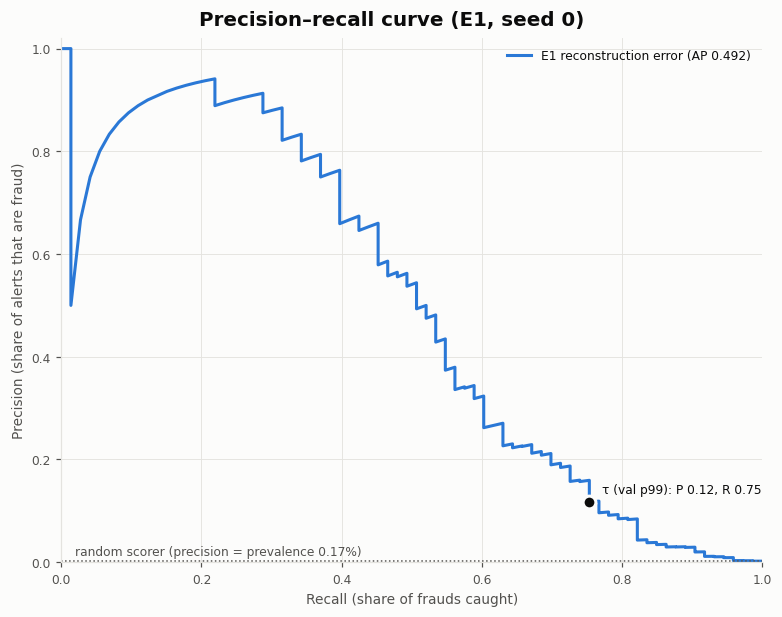

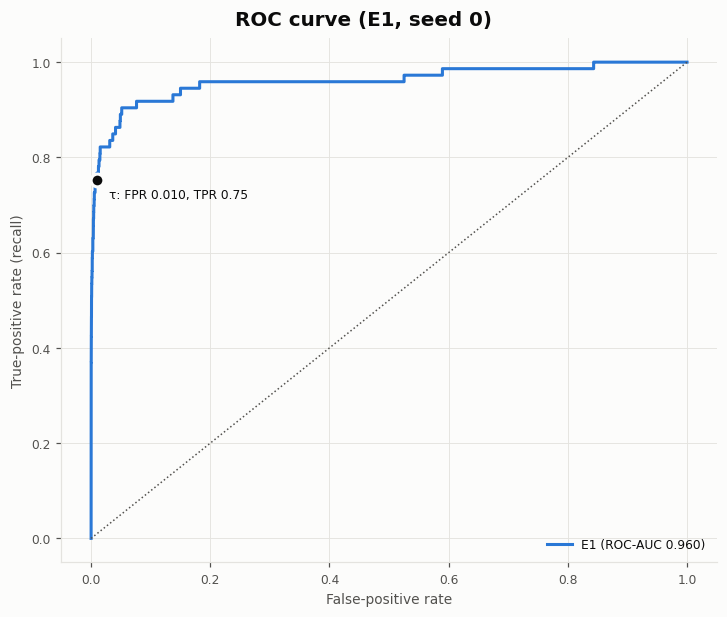

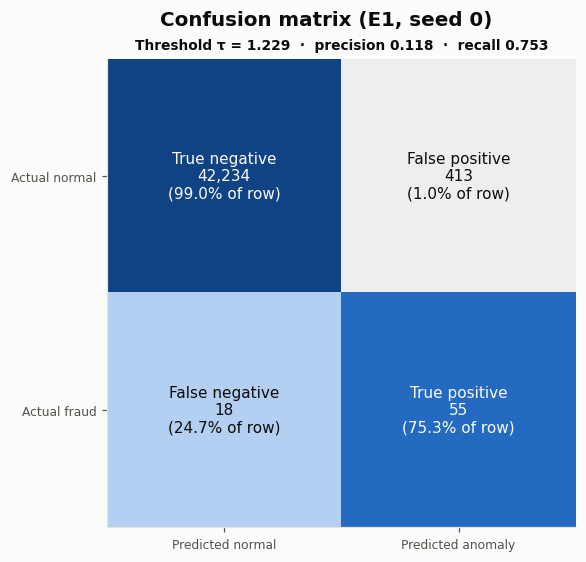

In [7]:
scores = np.load(run_dir(PROJECT_ROOT, "e1", 0) / "scores.npz")
y = load_test_labels(PROJECT_ROOT, data_cfg)   # predictions were already written (checked above)
s = scores["test_recon_mse"]
mp.plot_pr_curve({f"E1 reconstruction error (AP {p['average_precision']:.3f})": (y, s, NORMAL_COLOR)}, float(y.mean()),
                 {f"τ (val p99): P {p['precision']:.2f}, R {p['recall']:.2f}": (p["recall"], p["precision"])}, "Precision–recall curve (E1, seed 0)")
plt.show()
mp.plot_roc_curve({f"E1 (ROC-AUC {p['roc_auc']:.3f})": (y, s, NORMAL_COLOR)}, {f"τ: FPR {p['fpr']:.3f}, TPR {p['tpr']:.2f}": (p["fpr"], p["tpr"])},
                  "ROC curve (E1, seed 0)")
plt.show()
mp.plot_confusion_matrix(p, "Confusion matrix (E1, seed 0)")
plt.show()

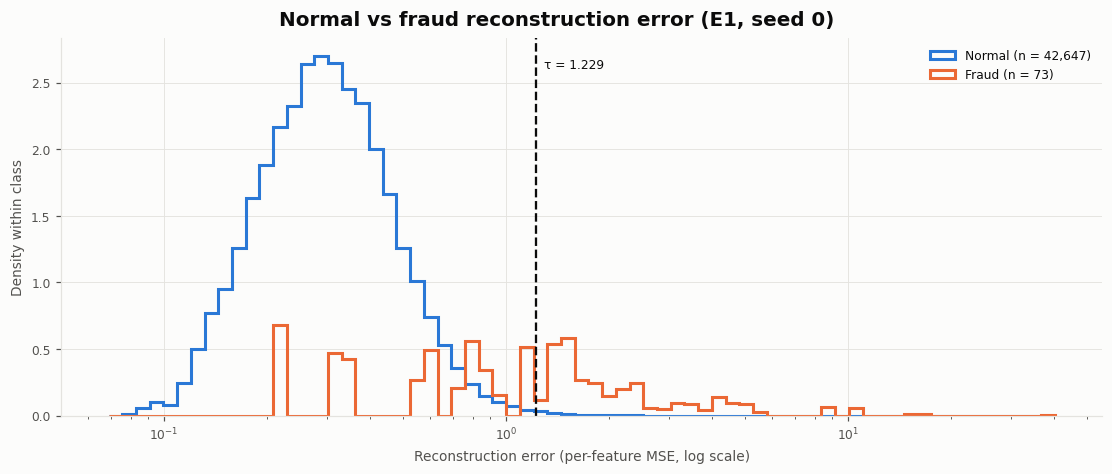

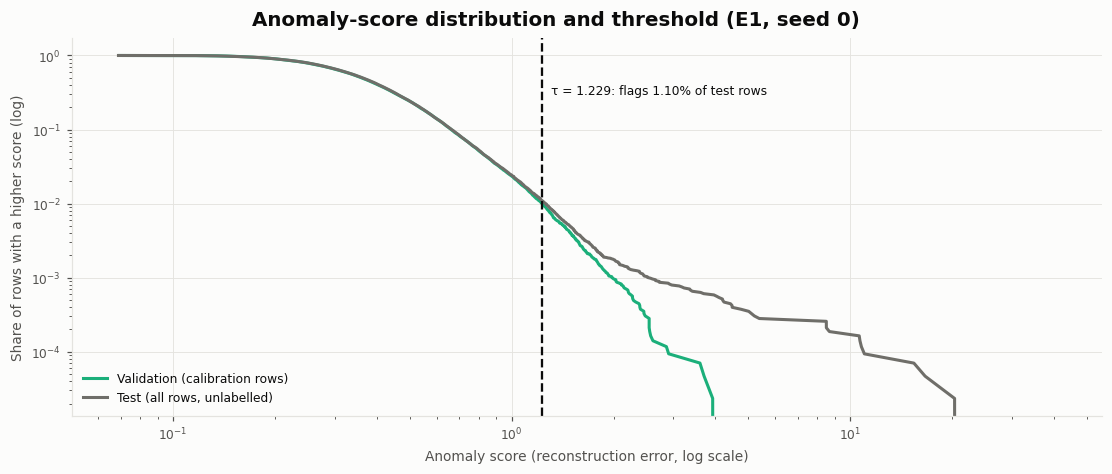

In [8]:
mp.plot_score_by_class(y, s, p["threshold"], "Normal vs fraud reconstruction error (E1, seed 0)")
plt.show()
mp.plot_score_distribution(s, scores["val_recon_mse"], p["threshold"], "Anomaly-score distribution and threshold (E1, seed 0)")
plt.show()

## 4. Threshold sensitivity (post-hoc; every threshold comes from validation percentiles)

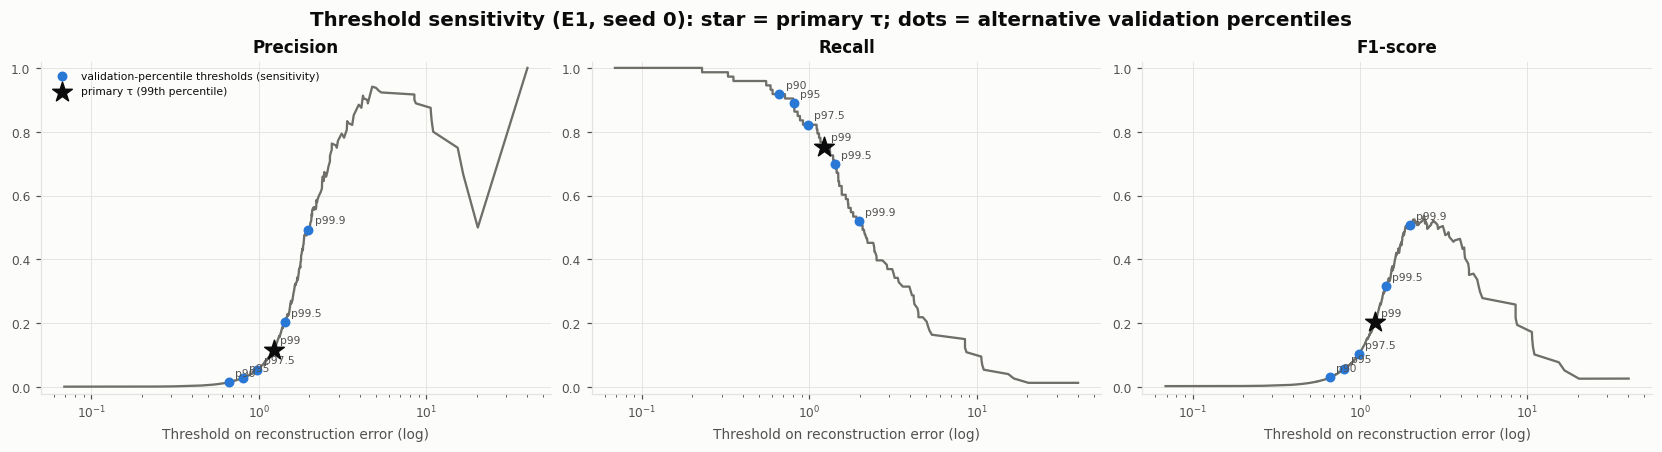

,validation_percentile,role,threshold,flagged,tp,fp,fn,precision,recall,f1,fpr
0,90.0,sensitivity,0.6627,4314,67,4247,6,0.0155,0.9178,0.0305,0.0996
1,95.0,sensitivity,0.8069,2171,65,2106,8,0.0299,0.8904,0.0579,0.0494
2,97.5,sensitivity,0.9815,1094,60,1034,13,0.0548,0.8219,0.1028,0.0242
3,99.0,primary,1.2292,468,55,413,18,0.1175,0.7534,0.2033,0.0097
4,99.5,sensitivity,1.4260,249,51,198,22,0.2048,0.6986,0.3168,0.0046
5,99.9,sensitivity,1.9801,77,38,39,35,0.4935,0.5205,0.5067,0.0009


In [9]:
sens = pd.read_csv(METRICS / "e1_threshold_sensitivity_headline.csv")
mp.plot_threshold_curves(y, s, sens, "Threshold sensitivity (E1, seed 0): star = primary τ; dots = alternative validation percentiles")
plt.show()
sens[["validation_percentile", "role", "threshold", "flagged", "tp", "fp", "fn", "precision", "recall", "f1", "fpr"]].round(4)

## 5. Secondary anomaly scores (likelihood-style estimates; still not fraud probabilities)

In [10]:
sec = per_seed[per_seed.experiment == "e1"][["seed", "average_precision", "ap_neg_elbo", "ap_iwae_nll"]]
display(sec.round(4))
sec[["average_precision", "ap_neg_elbo", "ap_iwae_nll"]].agg(["mean", "std"]).round(4)

,seed,average_precision,ap_neg_elbo,ap_iwae_nll
0,0,0.4922,0.4938,0.4375
1,1,0.4128,0.4663,0.4600
2,2,0.4608,0.4694,0.4412
3,3,0.3692,0.4260,0.3913
4,4,0.4229,0.3938,0.3699


,average_precision,ap_neg_elbo,ap_iwae_nll
mean,0.4316,0.4499,0.4200
std,0.0470,0.0397,0.0377


## 6. Secondary experiment: E2 (fully unsupervised, trained on all training rows with labels ignored)

In [11]:
cmp = load_json(METRICS / "detection_e1_vs_e2.json")
pd.DataFrame(cmp["per_seed_ap"]).round(4)

,E1 (normal-only),E2 (unsupervised)
0,0.4922,0.0300
1,0.4128,0.0297
2,0.4608,0.0308
3,0.3692,0.0316
4,0.4229,0.0665


Paired bootstrap, AP(E1) − AP(E2), seed 0: {'observed': 0.462, 'ci_low': 0.351, 'ci_high': 0.575, 'share_of_resamples_a_better': 1.0}


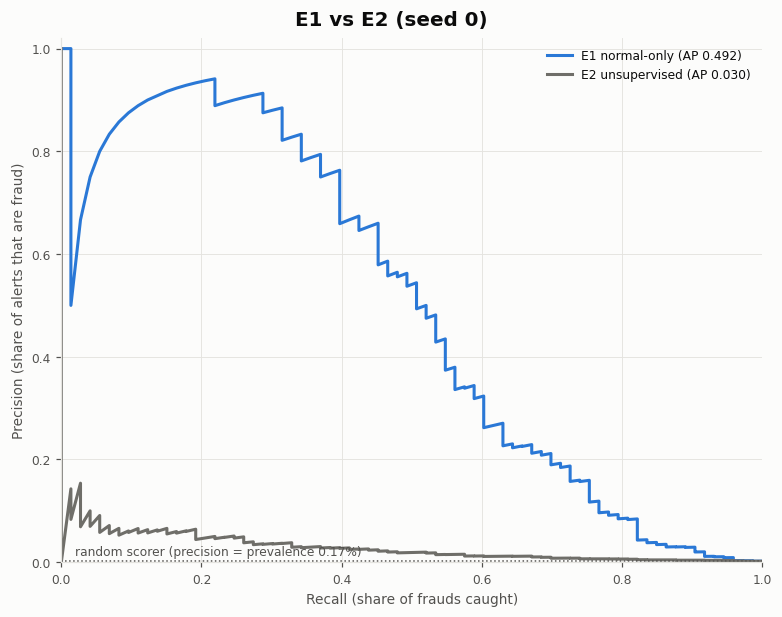

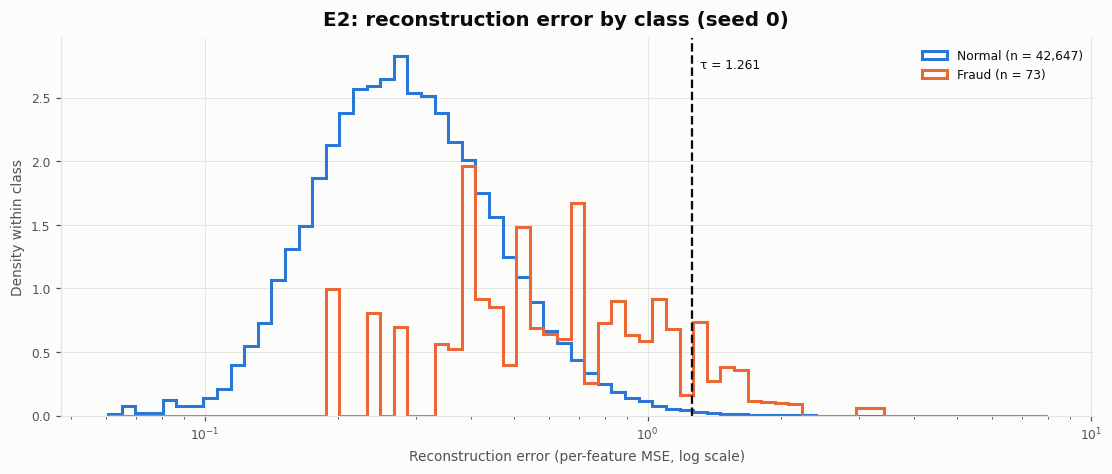

In [12]:
print("Paired bootstrap, AP(E1) − AP(E2), seed 0:", {k: round(v, 3) for k, v in cmp["paired_bootstrap_headline_seed"].items()})
e2_scores = np.load(run_dir(PROJECT_ROOT, "e2", 0) / "scores.npz")["test_recon_mse"]
m2 = load_json(METRICS / "e2_headline_metrics.json")["primary"]
mp.plot_pr_curve({f"E1 normal-only (AP {p['average_precision']:.3f})": (y, s, NORMAL_COLOR),
                  f"E2 unsupervised (AP {m2['average_precision']:.3f})": (y, e2_scores, mp.NEUTRAL)}, float(y.mean()), {}, "E1 vs E2 (seed 0)")
plt.show()
mp.plot_score_by_class(y, e2_scores, m2["threshold"], "E2: reconstruction error by class (seed 0)")
plt.show()

## 7. Error analysis (E1, seed 0)

In [13]:
df = load_raw(PROJECT_ROOT, data_cfg)
pred = pd.read_csv(run_dir(PROJECT_ROOT, "e1", 0) / "test_predictions.csv")
rows_ = df.iloc[pred["dataset_row"]]
tf = FeatureTransformer.load(processed_dir(PROJECT_ROOT, data_cfg) / "transformer_e1.json")
error_profile(rows_[TARGET_COL].to_numpy(), pred["predicted_anomaly"].to_numpy(), pred["recon_mse"].to_numpy(), tf.transform(rows_), rows_["Amount"].to_numpy()).round(3)

,rows,median_score,median_max_abs_z,share_any_abs_z_gt_5,median_amount
group,,,,,
TP,55,2.900,13.073,0.964,9.99
FN,18,0.811,5.562,0.722,8.37
FP,413,1.417,4.661,0.419,76.72
TN,42234,0.360,1.985,0.025,21.99


## 8. Interpretation

**Primary result (E1, normal-only VAE, 5 seeds):**
- **Average precision:** 0.432 ± 0.047 (seeds range 0.369–0.492), against **0.0017** for a random scorer, about 250× better.
- **ROC-AUC:** 0.947 ± 0.016.
- **At the validation-calibrated threshold:** recall 0.652 ± 0.072, precision 0.104 ± 0.013, F1 0.179 ± 0.021. The false-positive rate is 0.97% ± 0.07%, which matches the 1% target set on validation data, so the calibration transfers to unseen data.

**Headline model (seed 0):**
- **Note on seed 0:** it was fixed in advance and *happens to be the best of the five seeds*, so its numbers are above the typical result.
- **At τ:** it catches 55 of 73 test frauds (recall 0.753, 95% CI 0.644–0.849) and raises 413 false alarms. That is precision 0.118 (CI 0.100–0.134): about 1 in 8.5 alerts is a fraud, and 1.1% of transactions are flagged.
- **Ranking quality:** AP 0.492 (CI 0.376–0.618). The 100 highest-scoring transactions contain 40 frauds (precision 0.40).

**What the threshold choice means.**
- **Higher percentiles** trade recall for precision. At p99.9 the test precision is 0.49 and recall is 0.52 (F1 0.51); at p90 recall is 0.92 but precision is only 0.016.
- **p99.9 is not adopted.** It would give a higher test F1, but choosing it after looking at test results would be test-set tuning. The right operating point depends on how many alerts investigators can handle, which is a business decision, not a statistical one.

**Precision is the weak point.** With fraud at 0.17%, even a 1% false-positive rate means false alarms outnumber frauds about 7.5 to 1. This is the base-rate effect of extreme imbalance, not a calibration failure.

**Secondary scores.** The negative ELBO (AP 0.450 ± 0.040) and the importance-weighted likelihood estimate (0.420 ± 0.038) rank transactions about as well as reconstruction error. None of them is a fraud probability.

**E1 vs E2: contamination matters a lot.**
- **The gap:** the unsupervised E2 model reaches only AP 0.038 ± 0.016 (ROC-AUC 0.863, recall 0.263 at about the same 1% false-positive rate). E1 beats E2 in all 5 seeds; the paired bootstrap for seed 0 gives an AP difference of 0.46 (95% CI 0.35–0.58).
- **The cause:** the 345 training frauds are only 0.17% of E2's training rows but carry 4.1% of the total squared feature magnitude. Under squared-error training, E2 therefore learns to reconstruct them, and because frauds are strongly correlated with each other (EDA: |r| up to 0.97), that carries over to unseen frauds. E2's median reconstruction error on test frauds is 0.86, against 2.08 for E1.
- **What it means:** a "normal" training set that is even slightly contaminated can largely erase the reconstruction gap. The one-class protocol, which uses labels only to select training rows, is what makes this detector work.

**Errors.**
- **Missed frauds** have low reconstruction error (median 0.81 against τ = 1.23). Many still contain an extreme feature value but lie in regions the decoder reconstructs well.
- **False alarms** are mostly rare legitimate transactions: larger amounts (median 76.72 against 21.99 for normal), and 42% have at least one feature beyond |z| = 5.

**Limitations.**
- **Small test set:** only 73 test frauds, hence the wide confidence intervals; differences between seeds are within noise.
- **Old data:** results are for one 2-day dataset from 2013 with anonymised features.
- **Pre-scoring check:** the validation threshold was checked against the planned 1% false-positive target, not tuned.
- **No supervised comparison:** no supervised classifier was trained, by design. A supervised model trained with fraud labels would be expected to reach higher precision. The value of the VAE is that it needs **no fraud labels** to train.